# EDA – Steam: ¿qué hace que un juego sea bien recibido? (solo con información conocida al lanzamiento)


**Pregunta:** ¿Qué características *conocidas al lanzamiento* predicen la proporción de reseñas positivas?
**Objetivo (y):** `pct_pos = positivas / (positivas + negativas)`, solo para juegos con ≥ `MIN_REVIEWS` reseñas.


In [45]:
import os, re, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
SEED = 42; np.random.seed(SEED)
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 60, "display.width", 160)

DATA_DIR    = os.environ.get("DATA_DIR", "/kaggle/input")
MIN_REVIEWS = 50          # umbral del proyecto (se justifica en la sección 4)

In [46]:
import json, ast
def to_list(x):
    """Convierte listas guardadas como texto en lista de str.
    Soporta DOS formatos presentes en el dataset:
      ["Indie", ...]   y   [{'id': '23', 'description': 'Indie'}, ...]  (repr de Python, comillas simples)."""
    if isinstance(x, (list, tuple, np.ndarray)): v = list(x)
    elif pd.isna(x): return []
    else:
        v = None
        for parser in (json.loads, ast.literal_eval):
            try: v = parser(x); break
            except Exception: pass
        if v is None:
            s = re.sub(r"[\[\]'\"]", "", str(x)); return [t.strip() for t in s.split(",") if t.strip()]
    if not isinstance(v, list): return []
    return [str(t.get("description") or t.get("name") or "").strip() if isinstance(t, dict) else str(t).strip() for t in v]


## 1. Carga de datos

In [47]:
for f in glob.glob(f"{DATA_DIR}/**/*", recursive=True):
    if os.path.isfile(f): print(f"{os.path.getsize(f)/1e6:9.1f} MB  {f}")

   1145.2 MB  /kaggle/input/datasets/hubertsidorowicz/steam-games-dataset-daily-updates/steam_games.csv
      4.9 MB  /kaggle/input/datasets/hubertsidorowicz/steam-games-dataset-daily-updates/steam_games_reviews.csv


In [48]:
# Ajusta MAIN_FILE si hay varios archivos. Por defecto toma el CSV/parquet más grande.
cands = [f for f in glob.glob(f"{DATA_DIR}/**/*", recursive=True) if f.endswith((".csv", ".parquet"))]
MAIN_FILE = max(cands, key=os.path.getsize)
print("Archivo principal:", MAIN_FILE)

raw = pd.read_parquet(MAIN_FILE) if MAIN_FILE.endswith(".parquet") else pd.read_csv(MAIN_FILE, low_memory=False)
# nombres normalizados: minúsculas y guiones bajos
raw.columns = [re.sub(r"[^0-9a-z]+", "_", c.strip().lower()).strip("_") for c in raw.columns]
print(raw.shape); display(raw.head(3).T)

Archivo principal: /kaggle/input/datasets/hubertsidorowicz/steam-games-dataset-daily-updates/steam_games.csv
(150643, 42)


,0,1,2
app_id,1265390,1266480,1289500
name,EllrLand,MiNNaDe Counter Fight,BattleParty
release_date,2020-04-28,2020-05-01,2020-04-27
price,0.0,0.0,0.0
price_status,free,free,free
estimated_owners,0 - 20000,0 - 20000,0 - 20000
developers,"[""Sichuan fruit Interactive Technology Co., Ltd""]","[""Tricol Co., Ltd.""]","[""TeamNova""]"
publishers,"[""Sichuan fruit Interactive Technology Co., Ltd""]","[""Tricol Co., Ltd.""]","[""TeamNova""]"
genres,"[""Adventure"", ""Strategy""]","[""Action"", ""Casual"", ""Indie"", ""Early Access""]","[""Action"", ""Adventure"", ""Free To Play"", ""Indie..."
categories,"[""Single-player"", ""Family Sharing""]","[""Single-player"", ""Multi-player"", ""Co-op"", ""Sh...","[""Single-player"", ""Multi-player"", ""Co-op"", ""LA..."


In [49]:
raw.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150643 entries, 0 to 150642
Data columns (total 42 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   app_id                    150643 non-null  int64  
 1   name                      150627 non-null  object 
 2   release_date              150561 non-null  object 
 3   price                     149218 non-null  float64
 4   price_status              150643 non-null  object 
 5   estimated_owners          150643 non-null  object 
 6   developers                150643 non-null  object 
 7   publishers                150643 non-null  object 
 8   genres                    150643 non-null  object 
 9   categories                150643 non-null  object 
 10  tags                      150643 non-null  object 
 11  positive                  150643 non-null  int64  
 12  negative                  150643 non-null  int64  
 13  recommendations           97684 non-null   f

## 2. Mapa de columnas
Los nombres cambian entre versiones del dataset. Esta celda intenta detectarlos; **revisa la salida y corrige a mano** lo que quede en `None`.
Aquí también se declara qué columnas son **post-lanzamiento** (prohibidas como predictores → fuga).

In [50]:
def pick(*names):
    for n in names:
        if n in raw.columns: return n
    return None

COL = dict(
    app_id     = pick("appid","app_id","id"),
    name       = pick("name","title"),
    release    = pick("release_date","releasedate","date_release"),
    price      = pick("price","price_initial","initial_price","price_usd"),
    pos        = pick("positive","positive_reviews","num_positive","positive_ratings"),
    neg        = pick("negative","negative_reviews","num_negative","negative_ratings"),
    dev        = pick("developers","developer"),
    publisher  = pick("publishers","publisher"),
    genres     = pick("genres","genre"),
    categories = pick("categories","category"),
    tags       = pick("tags"),
    languages  = pick("supported_languages","languages","supported_language"),
    windows    = pick("windows"), mac = pick("mac"), linux = pick("linux"),
    age        = pick("required_age","age"),
    dlc        = pick("dlc_count","dlc"),
    achiev     = pick("achievements"),
    metacritic = pick("metacritic_score","metacritic"),
)
for k,v in COL.items(): print(f"{k:11s} -> {v}")

# Columnas POST-lanzamiento (se generan después de que el juego sale): nunca serán predictores
POST_CANDIDATES = ["estimated_owners","owners","peak_ccu","ccu","recommendations","num_reviews_total",
    "num_reviews_recent","reviews","pct_pos_total","pct_pos_recent","average_playtime_forever","average_playtime_2weeks",
    "median_playtime_forever","median_playtime_2weeks","average_playtime","median_playtime","user_score","score_rank",
    "positive","negative","discount","price_final","scores","tags_votes"]
POST = [c for c in POST_CANDIDATES if c in raw.columns]
print("\nColumnas post-lanzamiento detectadas:", POST)

app_id      -> app_id
name        -> name
release     -> release_date
price       -> price
pos         -> positive
neg         -> negative
dev         -> developers
publisher   -> publishers
genres      -> genres
categories  -> categories
tags        -> tags
languages   -> supported_languages
windows     -> windows
mac         -> mac
linux       -> linux
age         -> None
dlc         -> dlc_count
achiev      -> achievements
metacritic  -> metacritic_score

Columnas post-lanzamiento detectadas: ['estimated_owners', 'peak_ccu', 'recommendations', 'average_playtime_forever', 'average_playtime_2weeks', 'median_playtime_forever', 'median_playtime_2weeks', 'user_score', 'positive', 'negative']


In [51]:
# Si el archivo principal NO trae positivas/negativas, agrégalas desde el archivo de reseñas (join por app_id).
if COL["pos"] is None or COL["neg"] is None:
    print("No hay conteos de reseñas en el archivo principal. Ajusta aquí el archivo de reseñas:")
    # Ejemplo (ajusta nombres):
    # rev = pd.read_csv(f"{DATA_DIR}/.../reviews.csv", usecols=["app_id","voted_up"])
    # agg = rev.groupby("app_id")["voted_up"].agg(positive="sum", negative=lambda s: (~s.astype(bool)).sum()).reset_index()
    # raw = raw.merge(agg, left_on=COL["app_id"], right_on="app_id", how="left")
    # COL["pos"], COL["neg"] = "positive", "negative"

## 3. Calidad de datos 

In [52]:
df = raw.copy()
# Quita columnas de texto largo/multimedia: no se usan en el EDA y pesan mucho
heavy = ["about_the_game","detailed_description","short_description","header_image","screenshots","movies",
         "website","support_url","support_email","metacritic_url","notes","packages"]
long_txt = [c for c in heavy if c in df.columns]
long_txt += [c for c in df.select_dtypes("object") if c not in long_txt and df[c].dropna().astype(str).str.len().mean() > 300]
print("Columnas de texto largo descartadas:", long_txt)
df = df.drop(columns=long_txt)

# 3.1 Duplicados
n0 = len(df)
df = df.drop_duplicates(subset=COL["app_id"]) if COL["app_id"] else df.drop_duplicates()
print(f"Duplicados eliminados: {n0-len(df):,}  | filas: {len(df):,}")

# 3.2 Fechas
df["release_dt"] = pd.to_datetime(df[COL["release"]], errors="coerce")
print("Fechas inválidas/faltantes:", df["release_dt"].isna().sum())
print("Rango:", df["release_dt"].min(), "→", df["release_dt"].max())
print("Fechas futuras:", (df["release_dt"] > pd.Timestamp.today()).sum())
df["year"] = df["release_dt"].dt.year

Columnas de texto largo descartadas: ['about_the_game', 'detailed_description', 'short_description', 'header_image', 'screenshots', 'movies', 'website', 'support_url', 'support_email', 'metacritic_url', 'notes', 'packages']
Duplicados eliminados: 0  | filas: 150,643
Fechas inválidas/faltantes: 82
Rango: 1997-06-30 00:00:00 → 2026-11-21 00:00:00
Fechas futuras: 0


In [53]:
# 3.3 Faltantes (ordenados) + vacíos disfrazados ("", "[]", "None")
def disguised_na(s):
    if s.dtype != "object": return 0
    return s.dropna().astype(str).str.strip().isin(["", "[]", "{}", "None", "nan", "N/A"]).sum()

q = pd.DataFrame({"pct_nan": df.isna().mean()*100,
                  "n_vacios_disfrazados": [disguised_na(df[c]) for c in df.columns],
                  "n_unicos": df.nunique()})
q["pct_nan_total"] = q["pct_nan"] + q["n_vacios_disfrazados"]/len(df)*100
display(q.sort_values("pct_nan_total", ascending=False).head(25).round(2))

,pct_nan,n_vacios_disfrazados,n_unicos,pct_nan_total
full_audio_languages,36.64,63418,2649,78.74
tags,0.00,67160,80756,44.58
metacritic_score,41.43,0,73,41.43
recommendations,35.16,0,5433,35.16
achievements,17.67,0,442,17.67
categories,0.00,8962,25183,5.95
publishers,0.00,8849,81128,5.87
developers,0.00,8449,89996,5.61
genres,0.00,8434,4334,5.60
supported_languages,0.02,8366,30514,5.57


In [54]:
# 3.4 Inconsistencias numéricas
chk = {}
if COL["price"]:  chk["precio < 0"] = (df[COL["price"]] < 0).sum(); chk["precio == 0 (gratis)"] = (df[COL["price"]] == 0).sum(); chk["precio > 200"] = (df[COL["price"]] > 200).sum()
if COL["pos"]:    chk["positivas < 0"] = (df[COL["pos"]] < 0).sum()
if COL["neg"]:    chk["negativas < 0"] = (df[COL["neg"]] < 0).sum()
if COL["name"]:   chk["nombre vacío"] = df[COL["name"]].isna().sum()
display(pd.Series(chk, name="n"))

# 3.5 ¿Hay columnas que indican la fuente (Steam Store vs SteamSpy)?  Úsalas para entender los faltantes.
src = ["steam_store_available", "steam_spy_available"]
src = [c for c in src if c in df.columns]
if len(src) == 2: display(pd.crosstab(df[src[0]], df[src[1]], margins=True))
if "steam_spy_available" in df.columns:
    sin_rev = (df[COL["pos"]].fillna(0) + df[COL["neg"]].fillna(0)) == 0
    print("% de juegos SIN reseñas según steam_spy_available (los ceros pueden ser faltantes, no 0 reales):")
    display(sin_rev.groupby(df["steam_spy_available"]).agg(["mean","sum"]))

precio < 0                  0
precio == 0 (gratis)    28702
precio > 200               18
positivas < 0               0
negativas < 0               0
nombre vacío               16
Name: n, dtype: int64

steam_spy_available,True,All
steam_store_available,,
False,14,14
True,150629,150629
All,150643,150643


% de juegos SIN reseñas según steam_spy_available (los ceros pueden ser faltantes, no 0 reales):


,mean,sum
steam_spy_available,,
True,0.448418,67551


**Anota para el reporte:** % de duplicados, fechas inválidas, columnas con muchos faltantes y qué decisión tomas (eliminar / imputar / indicador de faltante). Ojo: un faltante en `metacritic_score` es *informativo* (el juego no tiene crítica), no aleatorio.

## 4. Variable objetivo y umbral mínimo de reseñas
`pct_pos` con pocas reseñas es muy ruidosa (1/1 = 100 %). Se elige el umbral viendo cuántos juegos sobreviven y cómo cambia la dispersión.

In [55]:
df["n_rev"] = df[COL["pos"]].fillna(0) + df[COL["neg"]].fillna(0)
df["pct_pos"] = np.where(df["n_rev"] > 0, df[COL["pos"]] / df["n_rev"], np.nan)

print(f"Juegos con ≥1 reseña: {(df.n_rev>0).mean():.1%} de {len(df):,}")
thr = pd.DataFrame({t: {"n_juegos": int((df.n_rev>=t).sum()),
                        "% del total": (df.n_rev>=t).mean()*100,
                        "std pct_pos": df.loc[df.n_rev>=t,"pct_pos"].std(),
                        "media pct_pos": df.loc[df.n_rev>=t,"pct_pos"].mean()} for t in [1,10,30,50,100,200]}).T
display(thr.round(3))

Juegos con ≥1 reseña: 55.2% de 150,643


,n_juegos,% del total,std pct_pos,media pct_pos
1,83092.0,55.158,0.239,0.758
10,56777.0,37.690,0.179,0.772
30,37907.0,25.163,0.161,0.779
50,30698.0,20.378,0.155,0.785
100,22860.0,15.175,0.147,0.795
200,16704.0,11.088,0.140,0.806


Muestra de modelado: 30,695 juegos (≥50 reseñas, con datos de SteamSpy, fecha válida)


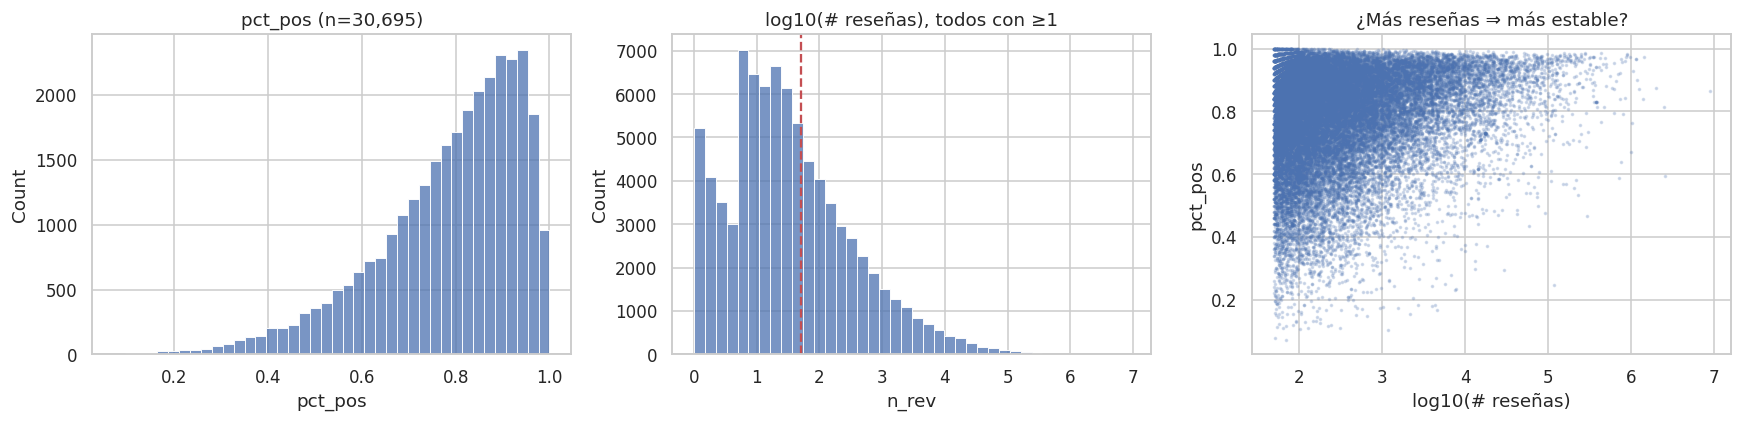

Asimetría: -1.08 | Cuantiles: [0.48, 0.7, 0.82, 0.9, 0.97]


In [56]:
ok_src = df["steam_spy_available"].astype(str).str.lower().eq("true") if "steam_spy_available" in df.columns else True
d = df[(df.n_rev >= MIN_REVIEWS) & ok_src & df["release_dt"].notna() & (df["release_dt"] <= pd.Timestamp.today())].copy()
print(f"Muestra de modelado: {len(d):,} juegos (≥{MIN_REVIEWS} reseñas, con datos de SteamSpy, fecha válida)")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(d["pct_pos"], bins=40, ax=ax[0]); ax[0].set_title(f"pct_pos (n={len(d):,})")
sns.histplot(np.log10(df.loc[df.n_rev>0,"n_rev"]), bins=40, ax=ax[1]); ax[1].set_title("log10(# reseñas), todos con ≥1")
ax[1].axvline(np.log10(MIN_REVIEWS), color="r", ls="--")
ax[2].scatter(np.log10(d["n_rev"]), d["pct_pos"], s=2, alpha=.2); ax[2].set_xlabel("log10(# reseñas)"); ax[2].set_ylabel("pct_pos"); ax[2].set_title("¿Más reseñas ⇒ más estable?")
plt.tight_layout(); plt.show()
print("Asimetría:", round(d["pct_pos"].skew(), 2), "| Cuantiles:", d["pct_pos"].quantile([.05,.25,.5,.75,.95]).round(2).tolist())

**Interpretación esperada:** la distribución suele ser asimétrica a la izquierda (mucha masa en 0.7–0.95). Eso afecta la elección de métricas (RMSE vs MAE) y motiva un baseline que prediga la media/mediana. Reporta el RMSE de ese baseline.

## 5. Variables pre-lanzamiento (EDA univariado y bivariado vs. `pct_pos`)

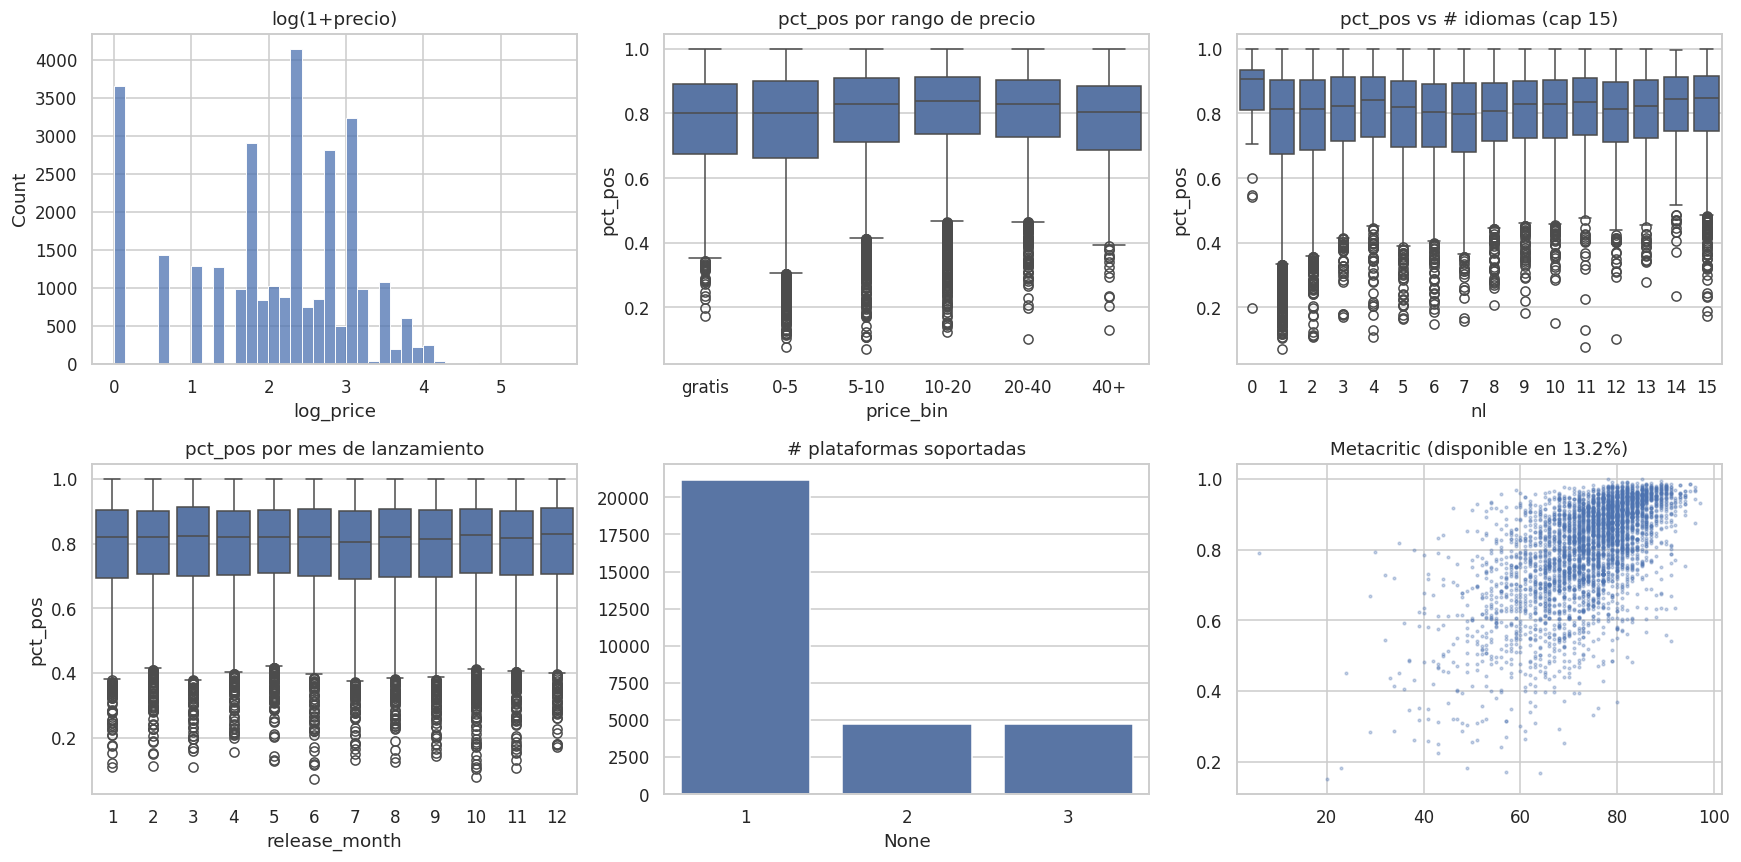

In [57]:
if COL["price"]:
    d["price"] = d[COL["price"]].clip(lower=0)
    d["log_price"] = np.log1p(d["price"]); d["is_free"] = (d["price"]==0).astype(int)
if COL["languages"]:
    d["n_languages"] = d[COL["languages"]].map(lambda x: len(to_list(x)))
for k in ["windows","mac","linux"]:
    if COL[k]: d[k] = d[COL[k]].astype(str).str.lower().isin(["true","1","1.0"]).astype(int)
d["release_month"] = d["release_dt"].dt.month
d["release_dow"]   = d["release_dt"].dt.dayofweek

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
if "log_price" in d:
    sns.histplot(d["log_price"], bins=40, ax=ax[0,0]); ax[0,0].set_title("log(1+precio)")
    d["price_bin"] = pd.cut(d["price"], [-.01,0,5,10,20,40,1e4], labels=["gratis","0-5","5-10","10-20","20-40","40+"])
    sns.boxplot(data=d, x="price_bin", y="pct_pos", ax=ax[0,1]); ax[0,1].set_title("pct_pos por rango de precio")
if "n_languages" in d:
    sns.boxplot(data=d.assign(nl=d.n_languages.clip(upper=15)), x="nl", y="pct_pos", ax=ax[0,2]); ax[0,2].set_title("pct_pos vs # idiomas (cap 15)")
sns.boxplot(data=d, x="release_month", y="pct_pos", ax=ax[1,0]); ax[1,0].set_title("pct_pos por mes de lanzamiento")
if "windows" in d:
    plat = d[["windows","mac","linux"]].sum(axis=1).value_counts().sort_index()
    sns.barplot(x=plat.index, y=plat.values, ax=ax[1,1]); ax[1,1].set_title("# plataformas soportadas")
if COL["metacritic"]:
    m = d[COL["metacritic"]].replace(0, np.nan)  # en este dataset 0 = sin calificación
    ax[1,2].scatter(m, d["pct_pos"], s=3, alpha=.3); ax[1,2].set_title(f"Metacritic (disponible en {m.notna().mean():.1%})")
plt.tight_layout(); plt.show()

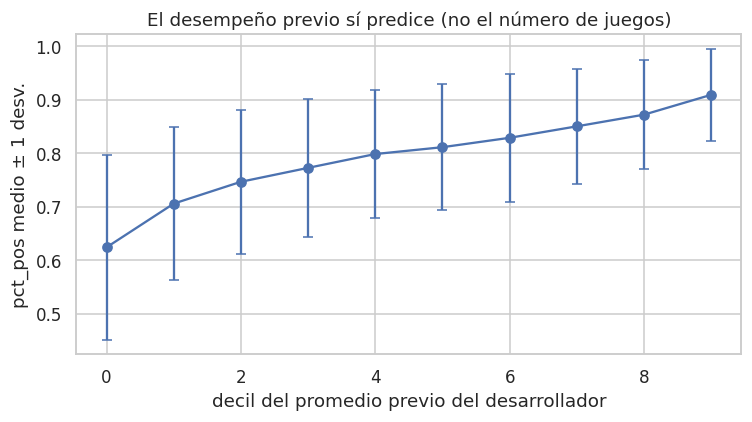

,mean,std,count
prev_bin,,,
"(0.11699999999999999, 0.599]",0.624,0.173,1258
"(0.599, 0.679]",0.706,0.143,1258
"(0.679, 0.733]",0.747,0.134,1258
"(0.733, 0.773]",0.773,0.129,1258
"(0.773, 0.806]",0.799,0.120,1258
"(0.806, 0.836]",0.811,0.118,1257
"(0.836, 0.865]",0.829,0.120,1258
"(0.865, 0.894]",0.850,0.108,1258
"(0.894, 0.928]",0.872,0.102,1258


In [64]:
ok = d.dropna(subset=["dev_prev_mean"]).copy()
ok["prev_bin"] = pd.qcut(ok["dev_prev_mean"], 10, duplicates="drop")
t = ok.groupby("prev_bin")["pct_pos"].agg(["mean", "std", "count"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(range(len(t)), t["mean"], yerr=t["std"], marker="o", capsize=3)
ax.set_xlabel("decil del promedio previo del desarrollador"); ax.set_ylabel("pct_pos medio ± 1 desv.")
ax.set_title("El desempeño previo sí predice (no el número de juegos)")
plt.tight_layout(); plt.show()
display(t.round(3))


## 6. Géneros y categorías (multi-hot)


== genres ==


,count,mean,std
item,,,
Indie,21118,0.790,0.153
Adventure,13230,0.791,0.152
Action,12898,0.772,0.157
Casual,10309,0.796,0.154
Simulation,7364,0.762,0.162
RPG,6866,0.779,0.148
Strategy,6695,0.764,0.153
Free To Play,2691,0.763,0.149
Early Access,2053,0.733,0.176


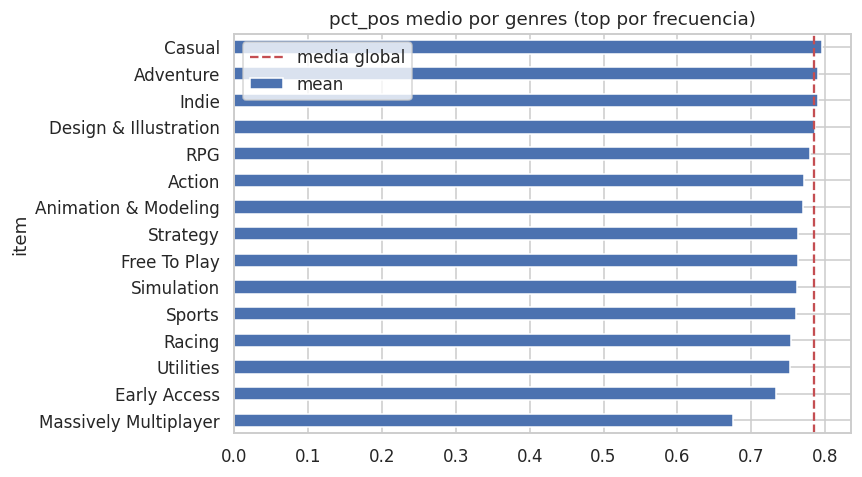


== categories ==


,count,mean,std
item,,,
Single-player,29006,0.789,0.154
Family Sharing,28868,0.785,0.155
Steam Achievements,20257,0.801,0.144
Steam Cloud,13511,0.820,0.131
Full controller support,9672,0.819,0.133
Steam Trading Cards,9333,0.781,0.148
Multi-player,7742,0.758,0.155
Partial Controller Support,4710,0.777,0.155
Co-op,4410,0.768,0.149


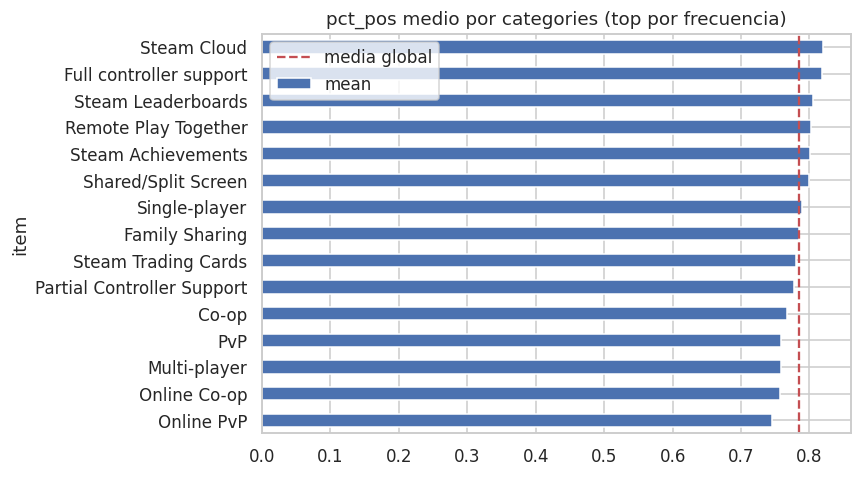

Cardinalidad de géneros: 28


In [58]:
def multi_hot_summary(col, top=15, min_n=100):
    L = d[col].map(to_list)
    exp = pd.DataFrame({"item": L, "y": d["pct_pos"]}).explode("item").dropna()
    g = exp.groupby("item")["y"].agg(["count","mean","std"]).query("count >= @min_n").sort_values("count", ascending=False)
    return g.head(top)

for key in ["genres","categories"]:
    if COL[key]:
        g = multi_hot_summary(COL[key]); print(f"\n== {key} =="); display(g.round(3))
        fig, ax = plt.subplots(figsize=(8, 4.5))
        g.sort_values("mean")["mean"].plot.barh(ax=ax); ax.axvline(d.pct_pos.mean(), color="r", ls="--", label="media global")
        ax.set_title(f"pct_pos medio por {key} (top por frecuencia)"); ax.legend(); plt.tight_layout(); plt.show()
if COL["genres"]:
    d["n_genres"] = d[COL["genres"]].map(to_list).map(len)
    print("Cardinalidad de géneros:", d[COL["genres"]].map(to_list).explode().nunique())

In [59]:
# Diagnóstico: ¿el formato (texto vs diccionario) de genres/categories depende del año? ¿se asocia con pct_pos?
def fmt_of(x): return "dict" if "description" in str(x) else "texto"
d["fmt_genres"] = d[COL["genres"]].map(fmt_of)
print("Proporción de formato 'dict' por año:")
print(pd.crosstab(d["year"], d["fmt_genres"], normalize="index").round(2).tail(15))
print("\npct_pos medio por formato (global y dentro de 2019-2024, para controlar el año):")
print(d.groupby("fmt_genres")["pct_pos"].agg(["count","mean"]).round(3))
print(d[d.year.between(2019, 2024)].groupby("fmt_genres")["pct_pos"].agg(["count","mean"]).round(3))


Proporción de formato 'dict' por año:
fmt_genres  dict  texto
year                   
2012.0      1.00   0.00
2013.0      1.00   0.00
2014.0      1.00   0.00
2015.0      1.00   0.00
2016.0      1.00   0.00
2017.0      1.00   0.00
2018.0      1.00   0.00
2019.0      1.00   0.00
2020.0      0.55   0.45
2021.0      0.27   0.73
2022.0      0.17   0.83
2023.0      0.11   0.89
2024.0      0.07   0.93
2025.0      0.07   0.93
2026.0      0.28   0.72

pct_pos medio por formato (global y dentro de 2019-2024, para controlar el año):
            count   mean
fmt_genres              
dict        18716  0.759
texto       11979  0.826
            count   mean
fmt_genres              
dict         5540  0.794
texto       10451  0.823


Decide para el reporte: ¿cuántos géneros/categorías/tags entran al multi-hot? (p. ej. los que aparezcan en ≥ 1 % de los juegos, el resto → `otros`). Los **tags** de usuario suelen tener votos posteriores al lanzamiento: úsalos con cuidado.

## 7. Tiempo: deriva y justificación de la partición
Si la distribución de `pct_pos` y de las covariables cambia con los años, una partición aleatoria sobreestima el desempeño. Esto justifica el split **temporal por fecha de lanzamiento**.

,n,media,mediana,precio_med
year,,,,
2012.0,309,0.762,0.809,9.99
2013.0,453,0.752,0.790,9.99
2014.0,1371,0.713,0.752,6.99
2015.0,1909,0.722,0.754,6.99
2016.0,2569,0.739,0.769,4.99
2017.0,2691,0.746,0.778,4.99
2018.0,2717,0.757,0.789,4.99
2019.0,2428,0.789,0.826,7.99
2020.0,2741,0.805,0.838,6.99


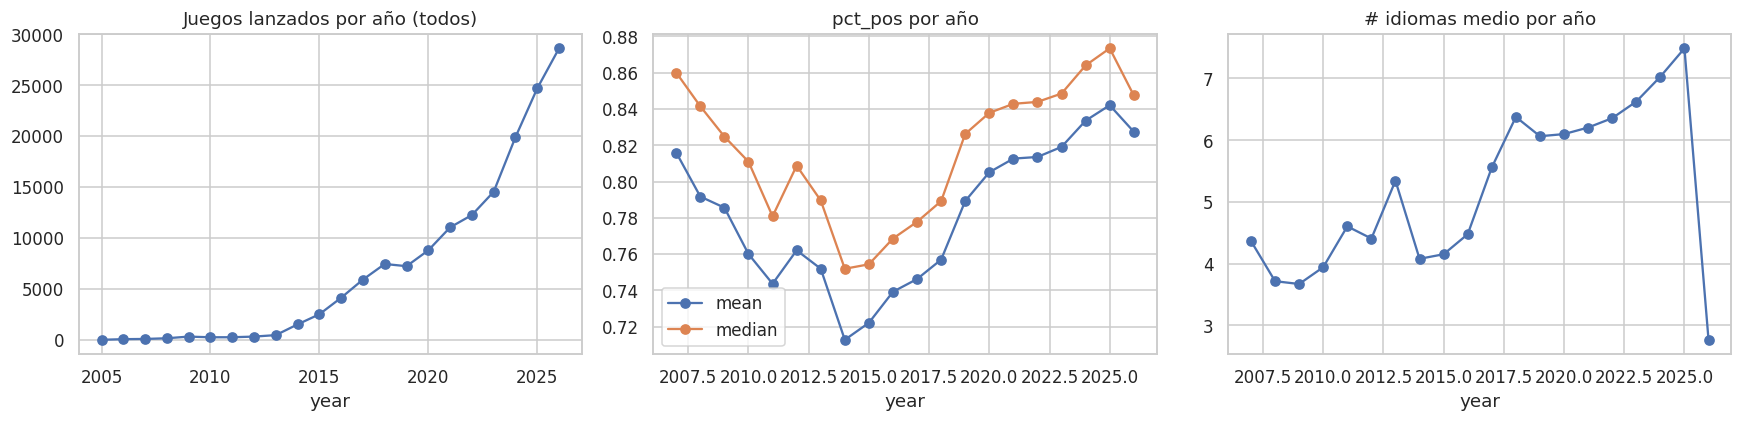

Cortes sugeridos train/valid/test: [datetime.date(2022, 4, 27), datetime.date(2024, 1, 31)]


In [60]:
agg = {"n": ("pct_pos","size"), "media": ("pct_pos","mean"), "mediana": ("pct_pos","median")}
if "price" in d: agg["precio_med"] = ("price","median")
by_year = d.groupby("year").agg(**agg)
display(by_year.tail(15).round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.groupby("year").size().loc[2005:].plot(ax=ax[0], marker="o"); ax[0].set_title("Juegos lanzados por año (todos)")
d.groupby("year")["pct_pos"].agg(["mean","median"]).loc[2007:].plot(ax=ax[1], marker="o"); ax[1].set_title("pct_pos por año")
if "n_languages" in d: d.groupby("year")["n_languages"].mean().loc[2007:].plot(ax=ax[2], marker="o"); ax[2].set_title("# idiomas medio por año")
plt.tight_layout(); plt.show()

# Propuesta de corte temporal (ajusta): ~70/15/15 por fecha
qs = d["release_dt"].quantile([.70, .85]); print("Cortes sugeridos train/valid/test:", qs.dt.date.tolist())

## 8. Historial del desarrollador (ingeniería de variables clave del proyecto)
Variable **sin fuga**: para cada juego, promedio de `pct_pos` de los juegos *anteriores* del mismo desarrollador (solo juegos elegibles, ≥ umbral). Se ordena por fecha y se resta el propio valor; el juego actual nunca entra en su promedio.

Juegos con ≥1 juego previo del mismo desarrollador: 41.0%
Desarrolladores únicos: 18050 | juegos por desarrollador (mediana): 1.0
Correlación Pearson  (historial vs pct_pos): 0.547
Correlación Spearman (historial vs pct_pos): 0.548


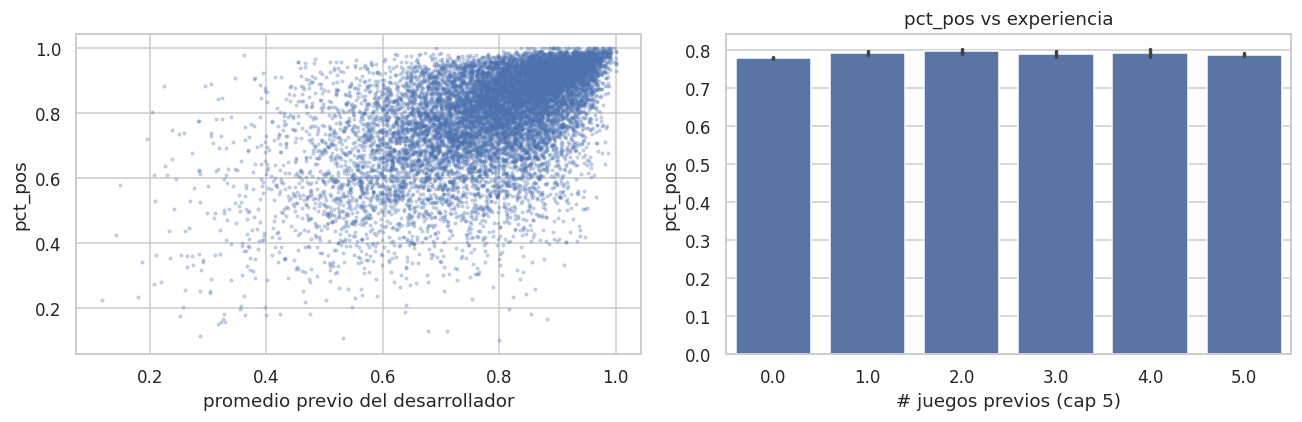

In [61]:
if COL["dev"]:
    d["dev1"] = d[COL["dev"]].map(to_list).map(lambda l: l[0] if l else np.nan)   # desarrollador principal
    d = d.sort_values("release_dt").reset_index(drop=True)
    g = d.groupby("dev1", sort=False)["pct_pos"]
    d["dev_prev_n"]    = g.cumcount()                                   # juegos previos elegibles
    d["dev_prev_mean"] = (g.cumsum() - d["pct_pos"]) / d["dev_prev_n"].replace(0, np.nan)
    d.loc[d.dev1.isna(), ["dev_prev_n","dev_prev_mean"]] = [0, np.nan]

    print(f"Juegos con ≥1 juego previo del mismo desarrollador: {(d.dev_prev_n>0).mean():.1%}")
    print("Desarrolladores únicos:", d.dev1.nunique(), "| juegos por desarrollador (mediana):", d.groupby('dev1').size().median())
    ok = d.dropna(subset=["dev_prev_mean"])
    print(f"Correlación Pearson  (historial vs pct_pos): {ok[['dev_prev_mean','pct_pos']].corr().iloc[0,1]:.3f}")
    print(f"Correlación Spearman (historial vs pct_pos): {ok[['dev_prev_mean','pct_pos']].corr('spearman').iloc[0,1]:.3f}")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].scatter(ok.dev_prev_mean, ok.pct_pos, s=3, alpha=.25); ax[0].set_xlabel("promedio previo del desarrollador"); ax[0].set_ylabel("pct_pos")
    sns.barplot(data=d.assign(k=d.dev_prev_n.clip(upper=5)), x="k", y="pct_pos", ax=ax[1]); ax[1].set_xlabel("# juegos previos (cap 5)"); ax[1].set_title("pct_pos vs experiencia")
    plt.tight_layout(); plt.show()

**Cuidado en el modelado:** en el pipeline final calcula esta variable solo con el pasado de cada juego (nunca con juegos posteriores ni con el `pct_pos` del propio juego). Los desarrolladores sin juegos previos (*cold start*) necesitan un valor de relleno + indicador. Nota: `pct_pos` de juegos previos se observa con retraso (las reseñas se acumulan); en un análisis más estricto, usa solo juegos lanzados al menos N meses antes.

## 9. Auditoría de fuga (data leakage)

In [62]:
post_in_d = [c for c in POST if c in d.columns and c not in (COL["pos"], COL["neg"])]
num_post = [c for c in post_in_d if pd.api.types.is_numeric_dtype(d[c])]
if num_post:
    leak = d[num_post + ["pct_pos"]].corr("spearman")["pct_pos"].drop("pct_pos").sort_values(key=abs, ascending=False)
    display(leak.to_frame("spearman vs pct_pos").round(3))
print("Excluir del modelo (post-lanzamiento / derivadas del objetivo):", sorted(set(POST + [COL['pos'], COL['neg'], 'n_rev', 'pct_pos'])))

,spearman vs pct_pos
peak_ccu,0.222
average_playtime_forever,0.145
median_playtime_forever,0.145
recommendations,0.117
median_playtime_2weeks,0.090
average_playtime_2weeks,0.090
user_score,0.015


Excluir del modelo (post-lanzamiento / derivadas del objetivo): ['average_playtime_2weeks', 'average_playtime_forever', 'estimated_owners', 'median_playtime_2weeks', 'median_playtime_forever', 'n_rev', 'negative', 'pct_pos', 'peak_ccu', 'positive', 'recommendations', 'user_score']


Las columnas post-lanzamiento (dueños, jugadores pico, tiempo de juego, `recommendations`, `user_score`…) pueden correlacionar fuerte con el objetivo; **justamente por eso** no se usan: no existen el día del lanzamiento. Incluye esta tabla en el reporte como evidencia de la decisión.

## 10. Correlaciones entre predictores pre-lanzamiento

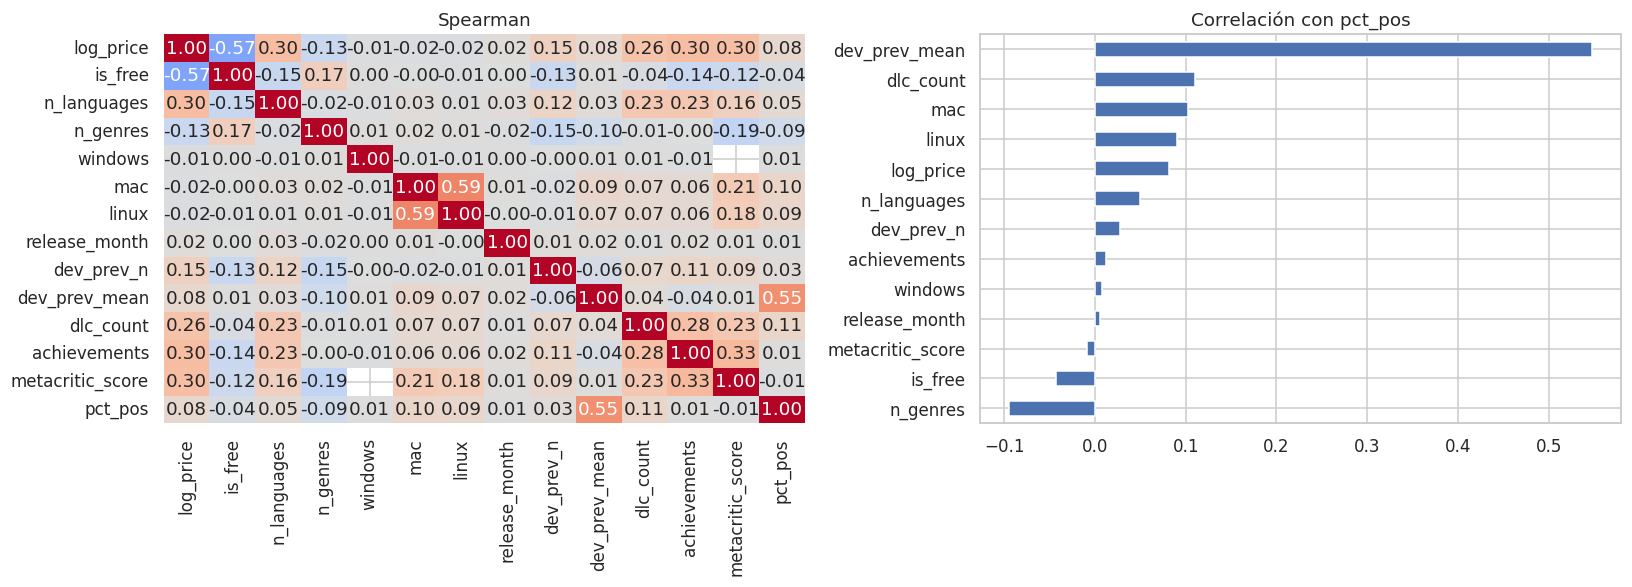

In [63]:
feat = [c for c in ["log_price","is_free","n_languages","n_genres","windows","mac","linux","release_month","dev_prev_n","dev_prev_mean"] if c in d.columns]
for k in ["age","dlc","achiev","metacritic"]:
    if COL[k] and pd.api.types.is_numeric_dtype(d[COL[k]]): feat.append(COL[k])
cm = d[feat + ["pct_pos"]].corr("spearman")
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[0], cbar=False); ax[0].set_title("Spearman")
cm["pct_pos"].drop("pct_pos").sort_values().plot.barh(ax=ax[1]); ax[1].set_title("Correlación con pct_pos")
plt.tight_layout(); plt.show()

## 11. Conclusiones del EDA → decisiones de modelado

| Hallazgo | Evidencia | Decisión |
| --- | --- | --- |
| Umbral | Con 50 reseñas quedan 30,695 juegos (20 %); la desviación baja a 0.155 | MIN_REVIEWS = 50; sensibilidad con 100 |
| Objetivo | Asimetría de −1.08; mediana de 0.82; 5 % de los juegos bajo 0.48 | Baseline por media o mediana del train; RMSE, MAE y R² |
| Faltantes | Metacritic 41 % nulo (0 equivale a sin calificar); tags 45 % vacío; audio [] 42 %; precio nulo 0.95 % | Indicadores has_*; n_audio_languages; precio con mediana más indicador |
| Deriva temporal | pct_pos medio de 0.71 (2014) a 0.84 (2025) | Split temporal; cortes cerca de 2022-04 y 2024-01 |
| Fechas inválidas | 82 (0.05 %) | Eliminar |
| Formato mixto | Dict hasta 2019 y texto después; artefacto del pipeline | Normalizar con to_list; no usar el formato como variable |
| Fuga | Variables post-lanzamiento con Spearman menor o igual a 0.22 | Excluir por disponibilidad temporal |
| Historial del desarrollador | Spearman de 0.548; 41 % con historial | Variable acumulada sin fuga; indicador de cold start; reportar con y sin historial |
| Transformaciones | Géneros: 28 únicos | log1p(precio), multi-hot (≥1 %), n_languages, n_audio_languages |

In [65]:
#Reglas de filtro, data
snap = df["release_dt"].max()
t = d.assign(edad=((snap - d["release_dt"]).dt.days/365.25).clip(upper=10),
             n_bin=pd.cut(d["n_rev"], [49, 100, 300, 1000, 1e9], labels=["50-100","100-300","300-1k","1k+"]))
t["edad_bin"] = pd.cut(t["edad"], [0, .5, 1, 2, 4, 10], labels=["<6m","6-12m","1-2a","2-4a","4a+"])
display(t.groupby("edad_bin")["pct_pos"].agg(["count","mean","std"]).round(3))
display(t.pivot_table(index="edad_bin", columns="n_bin", values="pct_pos", aggfunc="mean").round(3))


,count,mean,std
edad_bin,,,
<6m,39,0.815,0.105
6-12m,173,0.831,0.129
1-2a,1743,0.842,0.127
2-4a,5762,0.826,0.135
4a+,22978,0.770,0.159


n_bin,50-100,100-300,300-1k,1k+
edad_bin,,,,
<6m,0.777,0.809,0.822,0.826
6-12m,0.850,0.795,0.853,0.839
1-2a,0.846,0.845,0.831,0.845
2-4a,0.823,0.821,0.825,0.838
4a+,0.727,0.749,0.776,0.832


# Reglas de filtro y ponderación: conclusiones

**Proyecto:** Steam, ¿qué hace que un juego sea bien recibido? (solo con información conocida al lanzamiento)
**Objetivo:** `pct_pos` = reseñas positivas / reseñas totales

## 1. Contexto

`pct_pos` es ruidosa cuando hay pocas reseñas, y las reseñas de juegos recientes aún no maduran. Se evaluaron tres reglas para controlar ambos problemas:

1. **Umbral mínimo de reseñas:** excluir juegos con menos de N reseñas.
2. **Antigüedad mínima:** excluir juegos lanzados hace menos de N meses.
3. **Ponderación o suavizado:** dar más peso a juegos con más reseñas, o suavizar `pct_pos` hacia la media.

## 2. Evidencia

### 2.1 Efecto del umbral de reseñas

| Umbral | Juegos | Desv. de `pct_pos` | Media |
|---|---|---|---|
| 1 | 83,092 | 0.239 | 0.758 |
| 10 | 56,777 | 0.179 | 0.772 |
| 30 | 37,907 | 0.161 | 0.779 |
| 50 | 30,698 | 0.155 | 0.785 |
| 100 | 22,860 | 0.147 | 0.795 |
| 200 | 16,704 | 0.140 | 0.806 |

La dispersión cae rápido hasta 50 reseñas y después mejora poco. Con 50 quedan 30,695 juegos (20 % del total) tras filtrar fechas inválidas.

### 2.2 `pct_pos` por antigüedad (muestra con ≥ 50 reseñas)

| Antigüedad | Juegos | Media | Desv. |
|---|---|---|---|
| < 6 meses | 39 | 0.815 | 0.105 |
| 6–12 meses | 173 | 0.831 | 0.129 |
| 1–2 años | 1,743 | 0.842 | 0.127 |
| 2–4 años | 5,762 | 0.826 | 0.135 |
| 4+ años | 22,978 | 0.770 | 0.159 |

### 2.3 Media de `pct_pos` por antigüedad y número de reseñas

| Antigüedad | 50–100 | 100–300 | 300–1k | 1k+ |
|---|---|---|---|---|
| < 6 meses | 0.777 | 0.809 | 0.822 | 0.826 |
| 6–12 meses | 0.850 | 0.795 | 0.853 | 0.839 |
| 1–2 años | 0.846 | 0.845 | 0.831 | 0.845 |
| 2–4 años | 0.823 | 0.821 | 0.825 | 0.838 |
| 4+ años | 0.727 | 0.749 | 0.776 | 0.832 |

## 3. Hallazgos

1. **La dispersión no cae con la edad.** Los juegos con 4 o más años tienen la media más baja (0.770) y la desviación más alta (0.159). Los recientes son más homogéneos y mejor valorados. La diferencia es un **efecto de época** (deriva temporal), no un problema de reseñas inmaduras.
2. **El filtro de antigüedad cuesta casi nada.** Los juegos con menos de 12 meses son 212 (0.7 % de la muestra). Los de menos de 6 meses son solo 39, muy pocos para concluir algo sobre su volatilidad.
3. **Entre los juegos viejos, más reseñas significa mejor calificación.** En el grupo de 4 o más años la media sube de 0.727 (50–100 reseñas) a 0.832 (más de 1,000). En juegos recientes casi no cambia. Es un efecto de selección: solo los juegos muy buenos acumulan muchas reseñas con el tiempo.
4. **El 75 % de la muestra tiene 4 o más años.** Los juegos recientes, que serán el test temporal, se parecen poco a la mayoría del entrenamiento.

## 4. Decisión por regla

| Regla | Decisión | Justificación |
|---|---|---|
| **1. Umbral de reseñas** | **Mantener 50** como valor principal. Probar 30 y 100 como sensibilidad | Con 50 la dispersión ya cae a 0.155 y se conserva una muestra amplia. Bajar el umbral agregaría más juegos viejos con pocas reseñas, que son el grupo peor calificado y más heterogéneo |
| **2. Antigüedad mínima** | **Aplicar 12 meses**, igual en train y test | Es barata (212 juegos) y evita usar reseñas inmaduras. No se espera que mejore mucho el modelo |
| **3. Pesos o suavizado** | **No usar por defecto.** Probar solo como sensibilidad, evaluando siempre sin pesos | Pesar por número de reseñas empuja al modelo hacia juegos populares, y la sección 2.3 muestra que popularidad y calidad están asociadas. El suavizado hacia la media global tiene un sesgo pequeño con n = 50 (aprox. 0.008) pero crece si se baja el umbral |

## 5. Uso correcto de la antigüedad y el número de reseñas

- **Antigüedad:** solo como filtro de selección y para el historial del desarrollador (usar solo juegos con al menos N meses de antigüedad). **Nunca como variable predictora**, porque un juego nuevo siempre tiene antigüedad 0 al lanzamiento.
- **Número de reseñas:** solo como filtro o peso. **Nunca como variable predictora**, porque es información posterior al lanzamiento.
- **El año de lanzamiento** tampoco debe entrar como variable: el test cae en años que el modelo no vio.

## 6. Implicaciones para el modelado

- **Sesgo del baseline.** La media del entrenamiento (dominado por juegos de 4+ años, media 0.77) subestimará el test temporal (media 0.83–0.84) en unos 0.05. Hay que reportar ese sesgo.
- **Partición temporal** por fecha de lanzamiento, con la antigüedad mínima aplicada también al test.
- **Prueba de ventana de entrenamiento:** comparar entrenar con todo el histórico contra entrenar solo desde 2019, para ver si el efecto de época perjudica.
- **Evaluación:** siempre sin pesos y sobre `pct_pos` crudo.

## 7. Cuadrícula de sensibilidad propuesta

| Parámetro | Valores |
|---|---|
| Umbral de reseñas | 30, 50, 100 |
| Antigüedad mínima | 0 y 12 meses |
| Ventana de entrenamiento | todo el histórico, desde 2019 |
| Pesos de muestra | ninguno, n / (n + 50) |
| Evaluación | mismo test fijo: ≥ 50 reseñas, ≥ 12 meses, `pct_pos` crudo, sin pesos |

Valor por defecto: umbral 50, antigüedad 12 meses, sin pesos, todo el histórico. Las demás combinaciones se reportan como análisis de sensibilidad.

## 8. Limitaciones

- **Sesgo de selección:** filtrar por reseñas deja solo juegos con visibilidad, por lo que los resultados valen para juegos que alcanzan 50 reseñas.
- **Foto actual, no serie temporal:** no se puede medir cuánto tarda `pct_pos` en estabilizarse. La tabla por antigüedad es una aproximación transversal.
- **Antigüedad confundida con la época:** los juegos viejos tienen otra mezcla de reseñas y otro contexto de mercado, y no se pueden separar con una sola captura.
- **Pocos datos recientes:** los grupos de menos de 12 meses tienen muy pocos juegos, así que las conclusiones sobre ellos son tentativas.
